In [2]:
# Overview
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/boston_weather_raw.csv", parse_dates=["time"])
df = df.rename(columns={
    "temperature_2m_mean": "temp",
    "precipitation_sum": "precip",
    "wind_speed_10m_max": "wind",
    "snowfall_sum": "snow",
})

print("shape:", df.shape)
print("date range:", df["time"].min().date(), "to", df["time"].max().date())
print("duplicate dates:", df["time"].duplicated().sum())
print("date gaps:", (df["time"].diff().dropna() != pd.Timedelta("1D")).sum())
print("missing values:", df.isna().sum().sum())
df.describe().round(2)

shape: (7305, 5)
date range: 2006-01-01 to 2025-12-31
duplicate dates: 0
date gaps: 0
missing values: 0


,time,temp,precip,wind,snow
count,7305,7305.00,7305.00,7305.00,7305.00
mean,2016-01-01 00:00:00,11.12,3.14,20.60,0.26
min,2006-01-01 00:00:00,-17.40,0.00,6.80,0.00
25%,2011-01-01 00:00:00,3.80,0.00,15.70,0.00
50%,2016-01-01 00:00:00,11.30,0.00,19.50,0.00
75%,2020-12-31 00:00:00,19.00,2.50,24.20,0.00
max,2025-12-31 00:00:00,30.60,115.30,55.40,33.60
std,NaN,9.05,7.33,6.58,1.57


In [4]:
# Split the dataset
feature_cols = ["temp", "precip", "wind", "snow"]
lagged = pd.DataFrame({"target_date": df["time"], "y": df["temp"]})
for lag in (1, 2, 3):
    for c in feature_cols:
        lagged[f"{c}_lag{lag}"] = df[c].shift(lag)
lagged = lagged.dropna().reset_index(drop=True)

X_cols = [c for c in lagged.columns if "_lag" in c]
print("n features:", len(X_cols))

year = lagged["target_date"].dt.year
train = lagged[year <= 2017]
val = lagged[(year >= 2018) & (year <= 2021)]
test = lagged[year >= 2022]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(part):5d} rows ({len(part)/len(lagged):.0%}), "
          f"{part['target_date'].min().date()} to {part['target_date'].max().date()}")
lagged.head()

n features: 12
train:  4380 rows (60%), 2006-01-04 to 2017-12-31
val:  1461 rows (20%), 2018-01-01 to 2021-12-31
test:  1461 rows (20%), 2022-01-01 to 2025-12-31


,target_date,y,temp_lag1,precip_lag1,wind_lag1,snow_lag1,temp_lag2,precip_lag2,wind_lag2,snow_lag2,temp_lag3,precip_lag3,wind_lag3,snow_lag3
0,2006-01-04,-0.1,2.0,21.1,30.3,10.71,1.6,1.7,11.9,0.56,-1.3,3.3,17.7,2.24
1,2006-01-05,1.5,-0.1,0.0,26.9,0.00,2.0,21.1,30.3,10.71,1.6,1.7,11.9,0.56
2,2006-01-06,1.6,1.5,2.8,13.8,1.12,-0.1,0.0,26.9,0.00,2.0,21.1,30.3,10.71
3,2006-01-07,-2.1,1.6,0.0,18.9,0.00,1.5,2.8,13.8,1.12,-0.1,0.0,26.9,0.00
4,2006-01-08,-0.6,-2.1,0.0,21.0,0.00,1.6,0.0,18.9,0.00,1.5,2.8,13.8,1.12


In [8]:
# Prepare Data
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

base = df[df["time"].dt.year <= 2017].copy()
base["month"] = base["time"].dt.month

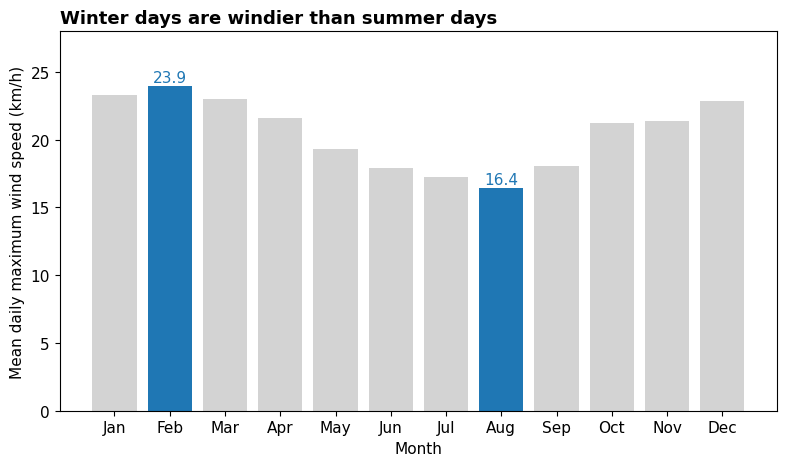

In [37]:
# Figure: mean daily maximum wind speed by month (training period)# Figure: distribution of each weather variable (training period, 2006-2017)
wind_m = base.groupby("month")["wind"].mean()
hi, lo = int(np.argmax(wind_m.values)), int(np.argmin(wind_m.values))
cols = ["lightgray"] * 12
cols[hi] = "tab:blue"
cols[lo] = "tab:blue"

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(months, wind_m.values, color=cols)
ax.text(hi, wind_m.values[hi] + 0.3, f"{wind_m.values[hi]:.1f}", ha="center", color="tab:blue")
ax.text(lo, wind_m.values[lo] + 0.3, f"{wind_m.values[lo]:.1f}", ha="center", color="tab:blue")
ax.set_xlabel("Month")
ax.set_ylabel("Mean daily maximum wind speed (km/h)")
ax.set_ylim(0, 28)
ax.set_title("Winter days are windier than summer days", loc="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/fig1_wind_by_month.png", dpi=200)
plt.show()plt.rcParams.update({"font.size": 11})
rain = base.loc[base["precip"] > 0, "precip"]
snow = base.loc[base["snow"] > 0, "snow"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].hist(base["temp"], bins=50, color="tab:red", alpha=0.8)
axes[0, 0].set_xlabel("Daily mean temperature (°C)")
axes[0, 0].set_ylabel("Number of days")

axes[0, 1].hist(base["wind"], bins=40, color="tab:gray")
axes[0, 1].set_xlabel("Daily maximum wind speed (km/h)")
axes[0, 1].set_ylabel("Number of days")

axes[1, 0].hist(rain, bins=np.logspace(np.log10(0.05), np.log10(rain.max()), 16), log=True, color="tab:blue")
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlabel("Daily precipitation (mm), days above 0 only")
axes[1, 0].set_ylabel("Number of days (log scale)")
axes[1, 0].set_title(f"No precipitation on {(base['precip'] == 0).mean():.0%} of days", fontsize=10, loc="right")

axes[1, 1].hist(snow, bins=np.logspace(np.log10(0.05), np.log10(snow.max()), 16), log=True, color="tab:purple")
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("Daily snowfall (cm), days above 0 only")
axes[1, 1].set_ylabel("Number of days (log scale)")
axes[1, 1].set_title(f"No snowfall on {(base['snow'] == 0).mean():.0%} of days", fontsize=10, loc="right")

fig.suptitle("Rain and snow are often absent; temperature spans −17 to 31 °C",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/fig1_distributions.png", dpi=200)
plt.show(

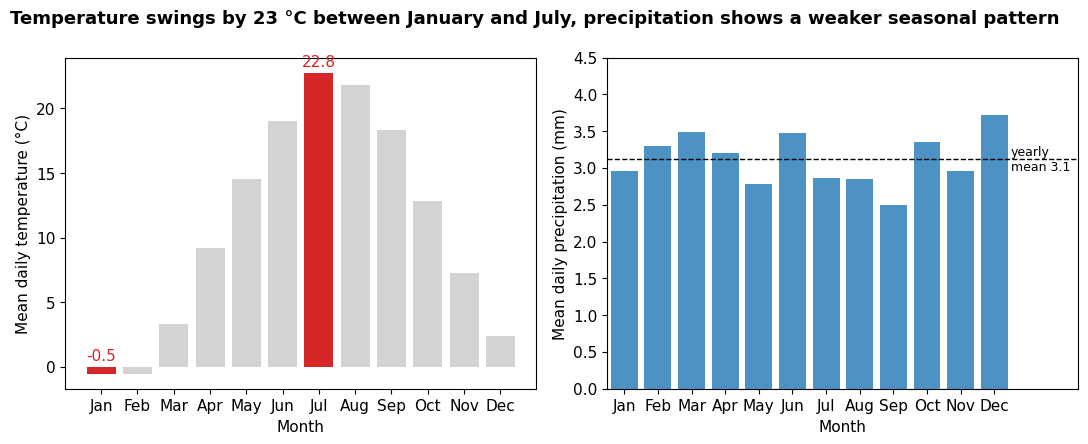

In [40]:
# Figure: seasonal cycle of temperature vs precipitation (training period)
g = base.groupby("month")
mt, mp = g["temp"].mean(), g["precip"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cols = ["lightgray"] * 12
cols[0] = "tab:red"
cols[6] = "tab:red"
axes[0].bar(months, mt.values, color=cols)
axes[0].set_ylabel("Mean daily temperature (°C)")
axes[0].set_xlabel("Month")
axes[0].text(0, 0.5, f"{mt.values[0]:.1f}", ha="center", color="tab:red")
axes[0].text(6, mt.values[6] + 0.5, f"{mt.values[6]:.1f}", ha="center", color="tab:red")

axes[1].bar(months, mp.values, color="tab:blue", alpha=0.8)
axes[1].axhline(mp.mean(), color="black", ls="--", lw=1)
axes[1].set_xlim(-0.5, 13.5)
axes[1].text(11.5, mp.mean(), f"yearly\nmean {mp.mean():.1f}", ha="left", va="center", fontsize=9)
axes[1].set_ylabel("Mean daily precipitation (mm)")
axes[1].set_xlabel("Month")
axes[1].set_ylim(0, 4.5)

fig.suptitle("Temperature swings by 23 °C between January and July, precipitation shows a weaker seasonal pattern",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/fig2_seasonality_contrast.png", dpi=200)
plt.show()

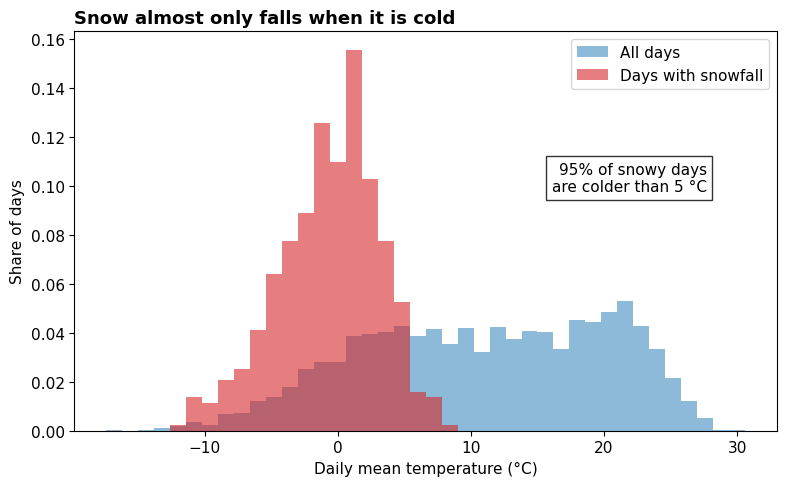

In [35]:
# Figure 3: daily mean temperature on all days vs days with snowfall (training period).
snowy = base[base["snow"] > 0]
rng = (base["temp"].min(), base["temp"].max())
share_below5 = (snowy["temp"] < 5).mean()

w_all = np.ones(len(base)) / len(base) 
w_snow = np.ones(len(snowy)) / len(snowy)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(base["temp"], bins=40, range=rng, weights=w_all, alpha=0.5, label="All days")
ax.hist(snowy["temp"], bins=40, range=rng, weights=w_snow, alpha=0.6, color="tab:red", label="Days with snowfall")
ax.set_xlabel("Daily mean temperature (°C)")
ax.set_ylabel("Share of days")
ax.text(0.9, 0.6, f"{share_below5:.0%} of snowy days\nare colder than 5 °C",
        transform=ax.transAxes, ha="right", bbox={"facecolor": "white", "alpha": 0.8})
ax.legend(loc="upper right")
ax.set_title("Snow almost only falls when it is cold", loc="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/fig3_snow_vs_temperature.png", dpi=200)
plt.show()